# code_142 · Conditional diffusion and straight-path flow matching

**Book:** section 27.5. A self-contained generative-model laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_27_GUIDE.md), [run evidence](../CHAPTER_27_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_142).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=3342;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 3342


<a id="diffusion-and-transport-contract"></a>
 ## Share a task without equating distinct objectives
 Eighty generated entities each supply ten four-time-point sensor trajectories. Source48/development16/final16 whole entities remain disjoint. A known scenario regime changes a latent mode frequency and trajectory level. Source-only coordinate standardization serves both models. An actual epsilon-prediction DDPM uses60 linear beta steps0.001 to0.15, Gaussian forward corruption and ancestral reverse updates with posterior variance. A separate conditional flow-matching network learns straight independent Gaussian-to-data interpolations and target displacement. Each method receives rates0.001/0.003, each1,200 Adam updates, and its own fixed-noise development objective every100updates; final data select nothing. Gaussian/trajectory output coordinates are continuous summaries, not guaranteed physical fields. Twenty/eighty-step midpoint ODE sampling shares initial noise to measure numerical sensitivity. This is not a vision task and does not identify the straight transport path with a DDPM probability-flow ODE.


DDPM selected learning rate 0.003


Flow matching selected learning rate 0.003


,method,rate,development_own_objective,selected_update,updates,parameters
0,DDPM,0.001,0.166433,1200,1200,4932
1,DDPM,0.003,0.161529,1200,1200,4932
2,Flow matching,0.001,0.806425,1200,1200,4932
3,Flow matching,0.003,0.776160,1100,1200,4932


,method,condition,reference_records,generated_records,final_projected_Wasserstein,covariance_Frobenius_error,generated_positive_level_fraction,reference_positive_level_fraction,field_evaluations_per_sample
0,DDPM,0,131,1000,0.073988,0.084200,0.237,0.213740,60
1,Flow matching,0,131,1000,0.123144,0.159574,0.264,0.213740,160
2,DDPM,1,29,1000,0.106998,0.327199,0.595,0.551724,60
3,Flow matching,1,29,1000,0.085361,0.139495,0.585,0.551724,160


Common-noise midpoint refinement: [0.0017259839341319438, 0.0017865601312137306]


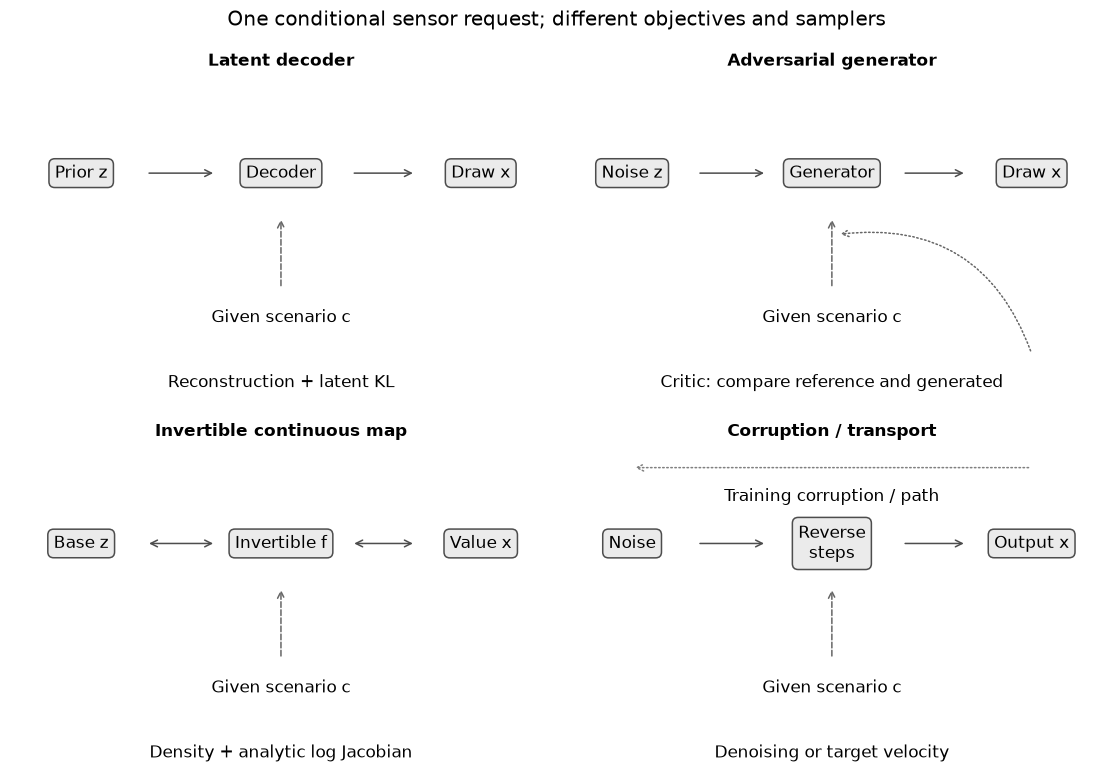

In [2]:
import copy
from scipy.stats import wasserstein_distance
B,R=80,10;entity=np.repeat(np.arange(B),R);condition=rng.binomial(1,.2,B*R);mode=rng.binomial(1,.25+.25*condition);level=1.5*(2*mode-1)+.5*condition+rng.normal(0,.2,B*R)+rng.normal(0,.1,B)[entity];slope=rng.normal(0,.25,B*R);times=np.linspace(-1,1,4);raw=level[:,None]+slope[:,None]*times+.35*np.sin(np.pi*times)[None,:]+rng.normal(0,.15,(B*R,4));source=entity<48;dev=(entity>=48)&(entity<64);final=entity>=64;center=raw[source].mean(0);spread=raw[source].std(0);z=(raw-center)/spread;X=torch.tensor(z);C=torch.tensor(condition[:,None]).double();si=torch.tensor(np.flatnonzero(source));di=torch.tensor(np.flatnonzero(dev));orders=[si[torch.tensor(rng.choice(len(si),128))] for _ in range(1200)];T=60;beta=torch.linspace(.001,.15,T);alpha=1-beta;abar=torch.cumprod(alpha,0);abar_previous=torch.cat([torch.ones(1),abar[:-1]]);posterior_variance=beta*(1-abar_previous)/(1-abar)
assert torch.all((beta>0)&(beta<1)) and torch.all(abar[1:]<abar[:-1]) and posterior_variance[0]==0
class Field(nn.Module):
    def __init__(self):super().__init__();self.net=nn.Sequential(nn.Linear(7,64),nn.SiLU(),nn.Linear(64,64),nn.SiLU(),nn.Linear(64,4))
    def forward(self,x,t,c):t=t.reshape(-1,1);return self.net(torch.cat([x,c,torch.sin(np.pi*t),torch.cos(np.pi*t)],1))
train_noise=torch.tensor(rng.normal(size=(1200,128,4)));train_index=torch.tensor(rng.integers(0,T,(1200,128)));train_t=torch.tensor(rng.uniform(size=(1200,128)));dev_noise=torch.tensor(rng.normal(size=(4,len(di),4)));dev_index=torch.tensor(rng.integers(0,T,(4,len(di))));dev_t=torch.tensor(rng.uniform(size=(4,len(di))));models={};fits=[]
for method in ['DDPM','Flow matching']:
    best_method=np.inf
    for rate in [.001,.003]:
        torch.manual_seed(SEED);model=Field();optimizer=torch.optim.Adam(model.parameters(),lr=rate);best=np.inf
        for step,ids in enumerate(orders):
            noise=train_noise[step]
            if method=='DDPM':j=train_index[step];aa=abar[j,None];noisy=aa.sqrt()*X[ids]+(1-aa).sqrt()*noise;step_time=j.double()/(T-1);target=noise
            else:step_time=train_t[step];noisy=(1-step_time[:,None])*noise+step_time[:,None]*X[ids];target=X[ids]-noise
            optimizer.zero_grad();prediction=model(noisy,step_time,C[ids]);loss=(prediction-target).square().mean();loss.backward();optimizer.step()
            if (step+1)%100==0:
                scores=[]
                with torch.no_grad():
                    for draw in range(4):
                        if method=='DDPM':j=dev_index[draw];aa=abar[j,None];noisy=aa.sqrt()*X[di]+(1-aa).sqrt()*dev_noise[draw];tt=j.double()/(T-1);target=dev_noise[draw]
                        else:tt=dev_t[draw];noisy=(1-tt[:,None])*dev_noise[draw]+tt[:,None]*X[di];target=X[di]-dev_noise[draw]
                        scores.append((model(noisy,tt,C[di])-target).square().mean())
                score=float(torch.stack(scores).mean())
                if score<best:best=score;state=copy.deepcopy(model.state_dict());best_step=step+1
        fits.append({'method':method,'rate':rate,'development_own_objective':best,'selected_update':best_step,'updates':1200,'parameters':sum(p.numel() for p in model.parameters())})
        if best<best_method:best_method=best;model.load_state_dict(state);models[method]=model;selected_rate=rate
    print(method,'selected learning rate',selected_rate)
@torch.no_grad()
def ddpm(initial,c):
    x=initial.clone();path=[float(x[0,0])]
    for j in reversed(range(T)):
        eps=models['DDPM'](x,torch.full((len(x),),j/(T-1)),c);mean=(x-beta[j]/torch.sqrt(1-abar[j])*eps)/torch.sqrt(alpha[j]);x=mean+torch.sqrt(posterior_variance[j])*torch.randn_like(x) if j>0 else mean;path.append(float(x[0,0]))
    return x.numpy(),path
@torch.no_grad()
def transport(initial,c,steps):
    x=initial.clone();dt=1/steps;path=[float(x[0,0])]
    for j in range(steps):
        t=torch.full((len(x),),j*dt);first=models['Flow matching'](x,t,c);mid=x+.5*dt*first;x=x+dt*models['Flow matching'](mid,t+.5*dt,c);path.append(float(x[0,0]))
    return x.numpy(),path
directions=rng.normal(size=(16,4));directions/=np.linalg.norm(directions,axis=1)[:,None]
def distance(a,b):return float(np.mean([wasserstein_distance(a@v,b@v) for v in directions]))
rows=[];generated={};paths={};refinements=[]
for c in [0,1]:
    initial=torch.tensor(rng.normal(size=(1000,4)));cc=torch.full((1000,1),float(c));diff,dpath=ddpm(initial,cc);flow20,fpath=transport(initial,cc,20);flow80,finepath=transport(initial,cc,80);refinements.append(float(np.sqrt(np.mean((flow80-flow20)**2))));actual=z[final&(condition==c)];natural_ref=raw[final&(condition==c)];generated[c]={'DDPM':diff,'Flow matching':flow80};paths[c]=(dpath,finepath)
    for method,sample in generated[c].items():
        natural=sample*spread+center;rows.append({'method':method,'condition':c,'reference_records':len(actual),'generated_records':len(sample),'final_projected_Wasserstein':distance(sample,actual),'covariance_Frobenius_error':float(np.linalg.norm(np.cov(sample.T)-np.cov(actual.T))),'generated_positive_level_fraction':float(np.mean(natural.mean(1)>0)),'reference_positive_level_fraction':float(np.mean(natural_ref.mean(1)>0)),'field_evaluations_per_sample':T if method=='DDPM' else 160})
# The declared straight path has the exact endpoint and displacement identities.
x0=torch.tensor([[1.,-2.,3.,-4.]]);x1=torch.tensor([[2.,1.,-1.,.5]]);torch.testing.assert_close((1-0.)*x0+0.*x1,x0);torch.testing.assert_close((1-1.)*x0+1.*x1,x1);torch.testing.assert_close((x1-x0)+x0,x1)
RESULTS.update(building_counts=[48,16,16],record_counts=[int(source.sum()),int(dev.sum()),int(final.sum())],fitting=fits,conditional_assessment=rows,ddpm_steps=T,ddpm_terminal_signal_fraction=float(abar[-1]),ddpm_beta_endpoints=[float(beta[0]),float(beta[-1])],flow_midpoint_steps=[20,80],flow_field_evaluations=[40,160],flow_common_initial_noise_RMS_refinement_by_condition=refinements);display(pd.DataFrame(fits));display(pd.DataFrame(rows));print('Common-noise midpoint refinement:',refinements)
fig,axes=plt.subplots(2,2,figsize=(10,7));mechanisms=[('Latent decoder','Prior z','Decoder','Draw x','Reconstruction + latent KL'),('Adversarial generator','Noise z','Generator','Draw x','Critic: compare reference and generated'),('Invertible continuous map','Base z','Invertible f','Value x','Density + analytic log Jacobian'),('Corruption / transport','Noise','Reverse\nsteps','Output x','Denoising or target velocity')]
for panel,(ax,(title,left,middle,right,objective)) in enumerate(zip(axes.ravel(),mechanisms)):
    ax.axis('off');ax.set(xlim=(0,1),ylim=(0,1));ax.text(.5,.94,title,ha='center',va='center',weight='bold');positions=[.13,.5,.87]
    for pos,label in zip(positions,[left,middle,right]):ax.text(pos,.63,label,ha='center',va='center',bbox={'boxstyle':'round,pad=.35','facecolor':'.92','edgecolor':'.3'})
    for lo,hi in [(.25,.38),(.63,.75)]:ax.annotate('',xy=(hi,.63),xytext=(lo,.63),arrowprops={'arrowstyle':'<->' if panel==2 else '->','color':'.3'})
    ax.text(.5,.23,'Given scenario c',ha='center',va='center');ax.annotate('',xy=(.5,.51),xytext=(.5,.31),arrowprops={'arrowstyle':'->','linestyle':'--','color':'.4'});ax.text(.5,.05,objective,ha='center',va='center')
    if panel==1:ax.annotate('',xy=(.51,.46),xytext=(.87,.13),arrowprops={'arrowstyle':'->','linestyle':':','connectionstyle':'arc3,rad=.4','color':'.4'})
    if panel==3:
        ax.annotate('',xy=(.13,.84),xytext=(.87,.84),arrowprops={'arrowstyle':'->','linestyle':':','color':'.5'});ax.text(.5,.76,'Training corruption / path',ha='center',va='center')
fig.suptitle('One conditional sensor request; different objectives and samplers');plt.show()


<a id="sampling-and-refinement"></a>
 ## Sampling accuracy and distributional accuracy remain separate
 DDPM begins with a standard Gaussian approximation to its terminal corrupted distribution and uses the explicitly chosen epsilon parameterization. Its sixty network evaluations include stochastic transitions; the last posterior variance is zero. The straight-path flow field is a different objective and uses a deterministic midpoint solver with forty or one hundred sixty network evaluations per generated sample. The common-initial-noise refinement isolates sensitivity to that ODE discretization. It does not estimate model bias or compare stochastic paths one-for-one. Conditional mode fractions and covariance errors are evaluated on independent final entities; their class sizes remain visible. The mechanism diagram aligns conceptual roles rather than asserting that the earlier notebooks use these same datasets or that the earlier unconditional coupling flow implements a conditional extension. No solver timing or universal quality ranking is claimed.


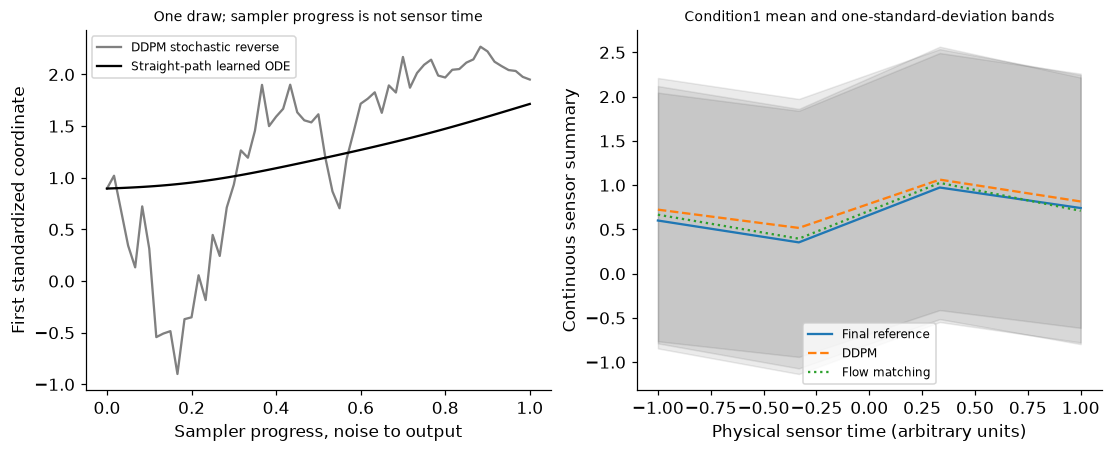

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));dpath,fpath=paths[1];axes[0].plot(np.linspace(0,1,len(dpath)),dpath,color='.5',label='DDPM stochastic reverse');axes[0].plot(np.linspace(0,1,len(fpath)),fpath,color='black',label='Straight-path learned ODE');axes[0].set(xlabel='Sampler progress, noise to output',ylabel='First standardized coordinate',title='One draw; sampler progress is not sensor time');axes[0].legend(fontsize=8)
reference=raw[final&(condition==1)]
for name,values,style in [('Final reference',reference,'-'),('DDPM',generated[1]['DDPM']*spread+center,'--'),('Flow matching',generated[1]['Flow matching']*spread+center,':')]:axes[1].plot(times,values.mean(0),style,label=name);axes[1].fill_between(times,values.mean(0)-values.std(0),values.mean(0)+values.std(0),alpha=.08,color='black')
axes[1].set(xlabel='Physical sensor time (arbitrary units)',ylabel='Continuous sensor summary',title='Condition1 mean and one-standard-deviation bands');axes[1].legend(fontsize=8);plt.show()
assert all(np.isfinite(r['final_projected_Wasserstein']) for r in rows)


In [4]:
summary={'example_id':'code_142','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual conditional DDPM epsilon prediction and ancestral sampling', 'native straight-path conditional flow matching', 'separate development objectives and fixed training budgets', 'ODE refinement with shared initial noise', 'mechanism alignment and trajectory distribution assessment'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual conditional DDPM epsilon prediction and ancestral sampling", "native straight-path conditional flow matching", "separate development objectives and fixed training budgets", "ODE refinement with shared initial noise", "mechanism alignment and trajectory distribution assessment"], "elapsed_seconds": 2.132, "example_id": "code_142", "hardware": "Darwin arm64 CPU", "results": {"building_counts": [48, 16, 16], "conditional_assessment": [{"condition": 0, "covariance_Frobenius_error": 0.08419977717100394, "field_evaluations_per_sample": 60, "final_projected_Wasserstein": 0.07398827105474226, "generated_positive_level_fraction": 0.237, "generated_records": 1000, "method": "DDPM", "reference_positive_level_fraction": 0.21374045801526717, "reference_records": 131}, {"condition": 0, "covariance_Frobenius_error": 0.15957420774558578, "field_evaluations_per_sample": 160, "final_projected_Wasserstein": 0.12314414933748694, "generated_positive